Тема 5. Законы распределения дискретных случайных величин

Привести примеры (сформулировать условие задачи, нельзя брать задачи из лекций и рассмотренные на практике из учебника) дискретных случайных величин, распределенных по: 
* биномиальному закону распределения; 
* закону распределения Пуассона;
* геометрическому закону распределения;
* гипергеометрическому закону распределения.

Для каждой ДСВ составить закон распределения, найти математическое ожидание, дисперсию, среднее квадратическое отклонение и моду, отобразить многоугольник распределения.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson, geom, hypergeom
from math import comb, sqrt, floor, ceil
from IPython.display import display

plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True

def print_distribution(name, values, probs, expected, variance, modes, tail=0):
    table = pd.DataFrame({'Значение X': values, 'P(X = x)': probs})
    display(table.assign(**{'P(X = x)': table['P(X = x)'].round(6)}))
    print(f'Математическое ожидание M(X) = {expected:.6f}')
    print(f'Дисперсия D(X) = {variance:.6f}')
    print(f'Среднее квадратическое отклонение σ(X) = {sqrt(variance):.6f}')
    print(f'Мода = {modes}')
    print(f'Сумма показанных вероятностей = {sum(probs):.8f}')
    if tail > 0:
        print(f'Вероятность за пределами таблицы = {tail:.8f}')
    fig, ax = plt.subplots()
    ax.plot(values, probs, marker='o', linewidth=1.7)
    ax.set_xticks(values)
    ax.set_xlabel('Значения случайной величины X')
    ax.set_ylabel('P(X = x)')
    ax.set_title(name)
    plt.show()


## 1. Биномиальное распределение

В тестовой лаборатории независимо запускают **8 сборок** программного приложения. Вероятность обнаружить критическую ошибку в каждой сборке равна **0,25**. Случайная величина $X$ — число сборок, в которых обнаружена критическая ошибка.

Параметры: $n=8$, $p=0.25$.

**Закон распределения:**
$$P(X=k)=\binom{8}{k}(0.25)^k(0.75)^{8-k},\qquad k=0,1,\ldots,8.$$

**Числовые характеристики:**
$$M(X)=np,\qquad D(X)=np(1-p),\qquad \sigma(X)=\sqrt{D(X)}.$$
Мода биномиального распределения: $\lfloor(n+1)p\rfloor$; если $(n+1)p$ — целое число от 1 до $n$, моды две: $(n+1)p-1$ и $(n+1)p$.

,Значение X,P(X = x)
0,0,0.100113
1,1,0.266968
2,2,0.311462
3,3,0.207642
4,4,0.086517
5,5,0.023071
6,6,0.003845
7,7,0.000366
8,8,0.000015


Математическое ожидание M(X) = 2.000000
Дисперсия D(X) = 1.500000
Среднее квадратическое отклонение σ(X) = 1.224745
Мода = [2]
Сумма показанных вероятностей = 1.00000000


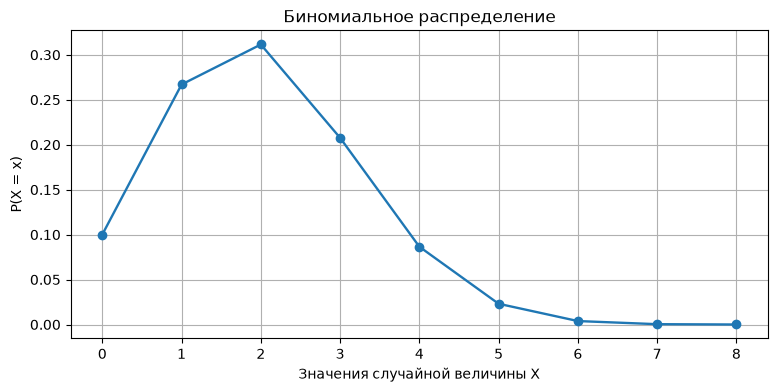

In [2]:
n, p = 8, 0.25
x = np.arange(0, n + 1)
probs = binom.pmf(x, n, p)
mu, var = n * p, n * p * (1 - p)
m = (n + 1) * p
modes = [int(m - 1), int(m)] if float(m).is_integer() and 1 <= m <= n else [floor(m)]
print_distribution('Биномиальное распределение', x, probs, mu, var, modes)
assert np.isclose(probs.sum(), 1)

## 2. Распределение Пуассона

В службе мониторинга облачного приложения в среднем поступает **2,4 предупреждения в час**. Предполагается, что предупреждения возникают независимо с постоянной интенсивностью. Случайная величина $X$ — количество предупреждений за один час.

Параметр: $\lambda=2.4$.

**Закон распределения:**
$$P(X=k)=\frac{e^{-2.4}2.4^k}{k!},\qquad k=0,1,2,\ldots$$

**Числовые характеристики:**
$$M(X)=\lambda,\qquad D(X)=\lambda,\qquad\sigma(X)=\sqrt{\lambda}.$$
Мода: $\lfloor\lambda\rfloor$ при нецелом $\lambda$; при положительном целом $\lambda$ — две моды: $\lambda-1$ и $\lambda$.


,Значение X,P(X = x)
0,0,0.090718
1,1,0.217723
2,2,0.261268
3,3,0.209014
4,4,0.125408
5,5,0.060196
6,6,0.024078
7,7,0.008255
8,8,0.002477
9,9,0.000660


Математическое ожидание M(X) = 2.400000
Дисперсия D(X) = 2.400000
Среднее квадратическое отклонение σ(X) = 1.549193
Мода = [2]
Сумма показанных вероятностей = 0.99999846
Вероятность за пределами таблицы = 0.00000154


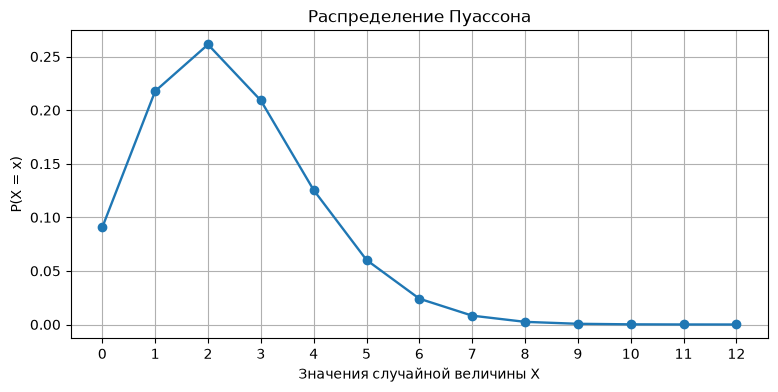

In [3]:
lam = 2.4
x = np.arange(0, 13)
probs = poisson.pmf(x, lam)
tail = poisson.sf(x[-1], lam)
modes = [floor(lam)] if not float(lam).is_integer() else [int(lam)-1, int(lam)]
print_distribution('Распределение Пуассона', x, probs, lam, lam, modes, tail)
assert np.isclose(probs.sum() + tail, 1)

## 3. Геометрическое распределение

Разработчик повторяет независимые попытки отправить пакет данных на тестовый сервер. Каждая попытка проходит успешно с вероятностью **0,3**. Случайная величина $X$ — **номер первой успешной попытки**, считая с единицы.

Параметр: $p=0.3$.

**Закон распределения:**
$$P(X=k)=(1-0.3)^{k-1}\cdot0.3,\qquad k=1,2,3,\ldots$$

**Числовые характеристики:**
$$M(X)=\frac{1}{p},\qquad D(X)=\frac{1-p}{p^2},\qquad\sigma(X)=\sqrt{D(X)}.$$
Мода равна 1.


,Значение X,P(X = x)
0,1,0.300000
1,2,0.210000
2,3,0.147000
3,4,0.102900
4,5,0.072030
5,6,0.050421
6,7,0.035295
7,8,0.024706
8,9,0.017294
9,10,0.012106


Математическое ожидание M(X) = 3.333333
Дисперсия D(X) = 7.777778
Среднее квадратическое отклонение σ(X) = 2.788867
Мода = [1]
Сумма показанных вероятностей = 0.99920208
Вероятность за пределами таблицы = 0.00079792


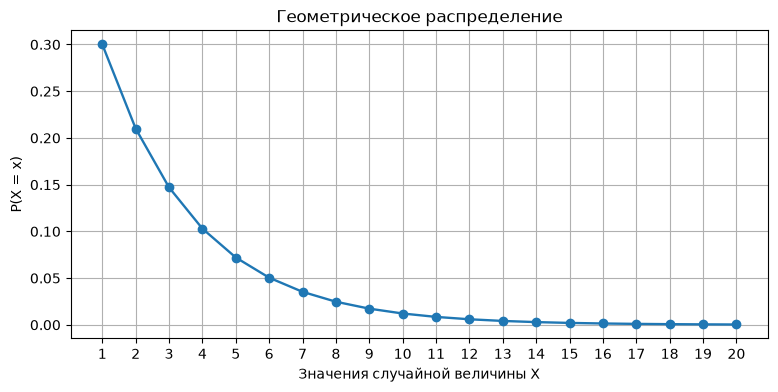

In [4]:
p = 0.3
x = np.arange(1, 21)
probs = geom.pmf(x, p)
mu, var = 1 / p, (1 - p) / p**2
tail = geom.sf(x[-1], p)
print_distribution('Геометрическое распределение', x, probs, mu, var, [1], tail)
assert np.isclose(probs.sum() + tail, 1)

## 4. Гипергеометрическое распределение

На складе находятся **20 сетевых адаптеров**, из них **7 имеют скрытый дефект**, а остальные 13 исправны. Для проверки случайно отбирают **5 адаптеров без возвращения**. Случайная величина $X$ — количество дефектных адаптеров в выборке.

Параметры: $N=20$ (всего), $K=7$ (дефектных), $n=5$ (выбирают).

**Закон распределения:**
$$P(X=k)=\frac{\binom{7}{k}\binom{13}{5-k}}{\binom{20}{5}},\qquad k=0,1,2,3,4,5.$$

**Числовые характеристики:**
$$M(X)=n\frac{K}{N},$$
$$D(X)=n\frac{K}{N}\left(1-\frac{K}{N}\right)\frac{N-n}{N-1},\qquad\sigma(X)=\sqrt{D(X)}.$$
Моду определим по наибольшему значению в таблице вероятностей.

,Значение X,P(X = x)
0,0,0.083011
1,1,0.322820
2,2,0.387384
3,3,0.176084
4,4,0.029347
5,5,0.001354


Математическое ожидание M(X) = 1.750000
Дисперсия D(X) = 0.898026
Среднее квадратическое отклонение σ(X) = 0.947643
Мода = [2]
Сумма показанных вероятностей = 1.00000000


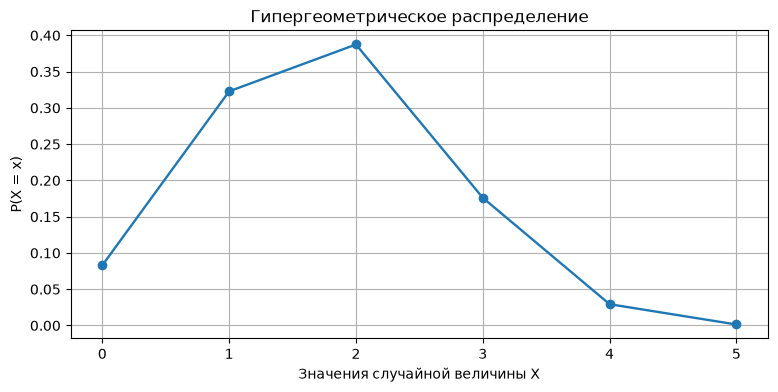

In [5]:
N, K, n = 20, 7, 5
x = np.arange(max(0, n - (N-K)), min(n, K) + 1)
probs = hypergeom.pmf(x, N, K, n)
mu = n * K / N
var = n * (K/N) * (1-K/N) * (N-n)/(N-1)
modes = x[np.isclose(probs, probs.max(), rtol=1e-12)].tolist()
print_distribution('Гипергеометрическое распределение', x, probs, mu, var, modes)
assert np.isclose(probs.sum(), 1)

In [6]:
summary = pd.DataFrame([
    ['Биномиальное', 8*.25, 8*.25*.75, [2]],
    ['Пуассона', 2.4, 2.4, [2]],
    ['Геометрическое', 1/.3, .7/.3**2, [1]],
    ['Гипергеометрическое', 5*7/20, 5*(7/20)*(13/20)*15/19,
     np.arange(0,6)[np.isclose(hypergeom.pmf(np.arange(0,6),20,7,5),hypergeom.pmf(np.arange(0,6),20,7,5).max())].tolist()],
], columns=['Распределение','M(X)','D(X)','Мода'])
summary['σ(X)'] = np.sqrt(summary['D(X)'])
display(summary[['Распределение','M(X)','D(X)','σ(X)','Мода']].round(5))

,Распределение,M(X),D(X),σ(X),Мода
0,Биномиальное,2.00000,1.50000,1.22474,[2]
1,Пуассона,2.40000,2.40000,1.54919,[2]
2,Геометрическое,3.33333,7.77778,2.78887,[1]
3,Гипергеометрическое,1.75000,0.89803,0.94764,[2]
